# Part 3 — Neural surrogate

**Question.** Once the simulator is accelerated by numba, does a neural network that replaces the simulations still bring anything to the GMM?

**Method.** Learn θ ↦ mean moments $E[c(\theta)]$ with an MLP trained on 20,000 simulations, then use it instead of the simulations in the Part 2 GMM.

**Outline.**
1. **3.2** Training set: Latin Hypercube Sampling, one simulation per point, train / validation / test split.
2. **3.3** Training (PyTorch, SiLU, early stopping) and evaluation: R², parity plots, noise floor.
3. **3.5** GMM with the surrogate, Monte Carlo on the 50 series of Part 2.
4. **3.6** Verdict: fixed cost, time per calibration, precision, break-even point.

**Requires** `abm.py`. Runtime: about 2 minutes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

In [2]:
# Part 2 setup: everything is defined in abm.py
from scipy.stats import qmc

from abm import THETA_TRUE, ESTIMATED_PARAMS, STAT_NAMES_2, full_theta, get_moments_2

x_true = np.array([THETA_TRUE[p] for p in ESTIMATED_PARAMS])

## 3.2 Training set

**Sampling**: 20,000 points x = (β, κ, σ) drawn by Latin Hypercube Sampling in the search box (each parameter's range is evenly covered).

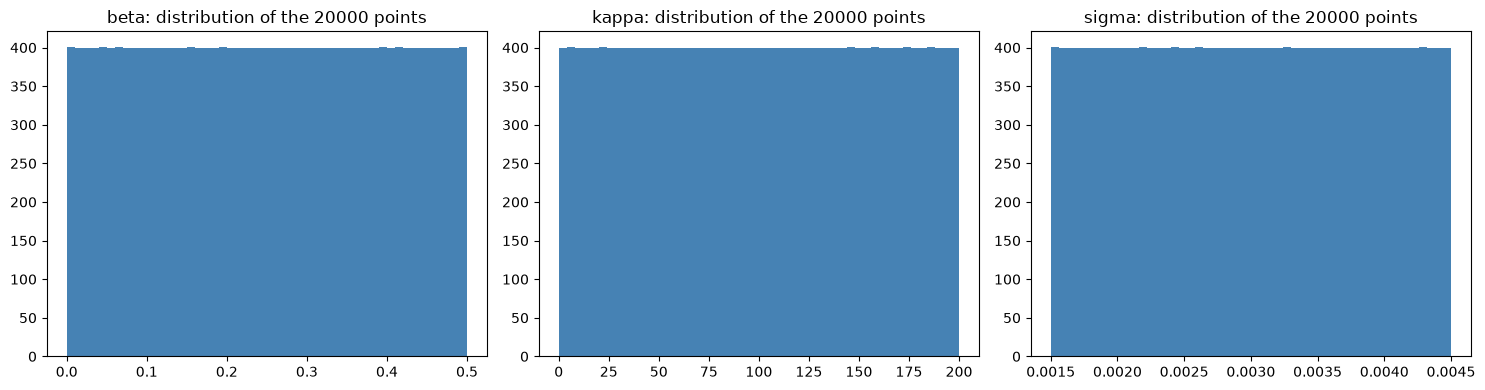

In [3]:
M = 20_000
surrogate_bounds = [(0, 0.5), (0, 200), (0.0015, 0.0045)]   # beta, kappa, sigma
low = np.array([a for a, _ in surrogate_bounds])
high = np.array([b for _, b in surrogate_bounds])

sampler = qmc.LatinHypercube(d=3, seed=0)
X = qmc.scale(sampler.random(M), low, high)   # (M, 3): one x = (beta, kappa, sigma) per row

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for j, name in enumerate(ESTIMATED_PARAMS):
    axes[j].hist(X[:, j], bins=50, color="steelblue")
    axes[j].set_title(f"{name}: distribution of the {M} points")
plt.tight_layout()
plt.show()

**Simulation**: one numba simulation per point (~0.6 ms each, no need to parallelize). Exploding runs are removed.

In [4]:
import time

t0 = time.perf_counter()
START_SEED = 100_000   # separate seeds: 100000, 100001, ... (≠ data, model, V)
Y = np.array([get_moments_2(full_theta(x), START_SEED + i) for i, x in enumerate(X)])   # (M, 4)
generation_time = time.perf_counter() - t0
print(f"{M} simulations in {generation_time:.0f} s")

valid = ~np.isnan(Y).any(axis=1)
print(f"Exploding simulations: {(~valid).sum()} ({100 * (~valid).mean():.1f} %)")
X, Y = X[valid], Y[valid]

20000 simulations in 17 s
Exploding simulations: 1038 (5.2 %)


**Train / validation / test split** (70 / 15 / 15 %) and **standardization** (statistics from the train set only).

In [5]:
rng_split = np.random.default_rng(1)
order = rng_split.permutation(len(X))
n_train, n_val = int(0.70 * len(X)), int(0.15 * len(X))
i_train, i_val, i_test = order[:n_train], order[n_train:n_train + n_val], order[n_train + n_val:]

X_train, Y_train = X[i_train], Y[i_train]
X_val, Y_val = X[i_val], Y[i_val]
X_test, Y_test = X[i_test], Y[i_test]

X_mean, X_std = X_train.mean(axis=0), X_train.std(axis=0)
Y_mean, Y_std = Y_train.mean(axis=0), Y_train.std(axis=0)

def norm_X(x): return (x - X_mean) / X_std
def norm_Y(y): return (y - Y_mean) / Y_std
def denorm_Y(y): return y * Y_std + Y_mean

print(f"train: {len(i_train)} | validation: {len(i_val)} | test: {len(i_test)}")
pd.DataFrame({"mean": Y_mean, "std": Y_std}, index=STAT_NAMES_2)

train: 13273 | validation: 2844 | test: 2845


,mean,std
std,0.003421,0.001789
acf1,0.070731,0.286664
acf2,0.105074,0.187036
acfabs1,0.143263,0.223497


## 3.3 Training and evaluating the surrogate

MLP 3 → 64 → 64 → 4, **SiLU** activation (smooth, since the network will be minimized), MSE loss, Adam, mini-batches of 256, **early stopping** on the validation set.

In [6]:
import copy

import torch
from torch import nn

torch.manual_seed(0)


def to_tensor(a):
    return torch.tensor(a, dtype=torch.float32)


Xt_train, Yt_train = to_tensor(norm_X(X_train)), to_tensor(norm_Y(Y_train))
Xt_val, Yt_val = to_tensor(norm_X(X_val)), to_tensor(norm_Y(Y_val))

net = nn.Sequential(
    nn.Linear(3, 64), nn.SiLU(),
    nn.Linear(64, 64), nn.SiLU(),
    nn.Linear(64, 4),
)
net

Sequential(
  (0): Linear(in_features=3, out_features=64, bias=True)
  (1): SiLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): SiLU()
  (4): Linear(in_features=64, out_features=4, bias=True)
)

**Training.** Each epoch goes through the whole train set in shuffled mini-batches. After each epoch, the validation loss is measured; the best weights are kept and training stops after 30 epochs without progress, so the network does not memorize the target noise.

132 epochs in 105 s | best validation loss: 0.36900


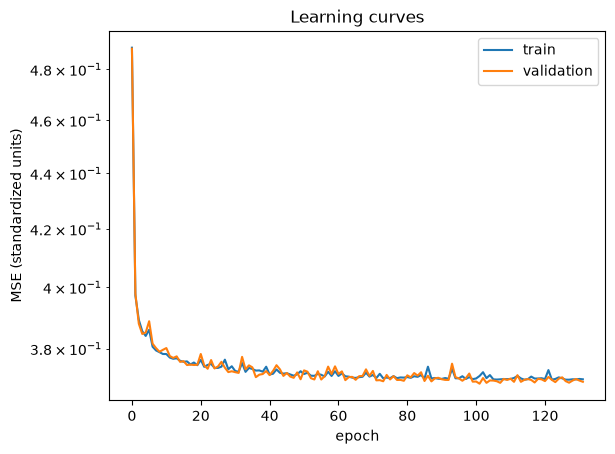

In [7]:
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
BATCH_SIZE, MAX_EPOCHS, PATIENCE = 256, 500, 30

train_history, val_history = [], []
best_val, best_weights, epochs_without_progress = np.inf, None, 0

t0 = time.perf_counter()
for epoch in range(MAX_EPOCHS):
    net.train()
    permutation = torch.randperm(len(Xt_train))
    for start in range(0, len(Xt_train), BATCH_SIZE):
        batch = permutation[start:start + BATCH_SIZE]
        optimizer.zero_grad()
        loss_fn(net(Xt_train[batch]), Yt_train[batch]).backward()
        optimizer.step()

    net.eval()
    with torch.no_grad():
        train_history.append(loss_fn(net(Xt_train), Yt_train).item())
        val_history.append(loss_fn(net(Xt_val), Yt_val).item())

    # Early stopping: keep the best weights, stop after PATIENCE epochs without progress
    if val_history[-1] < best_val:
        best_val, best_weights, epochs_without_progress = val_history[-1], copy.deepcopy(net.state_dict()), 0
    else:
        epochs_without_progress += 1
        if epochs_without_progress >= PATIENCE:
            break

net.load_state_dict(best_weights)
training_time = time.perf_counter() - t0
print(f"{epoch + 1} epochs in {training_time:.0f} s | best validation loss: {best_val:.5f}")

plt.semilogy(train_history, label="train")
plt.semilogy(val_history, label="validation")
plt.xlabel("epoch")
plt.ylabel("MSE (standardized units)")
plt.title("Learning curves")
plt.legend()
plt.show()

**Test-set evaluation**: R² and parity plots (simulated on x, predicted on y).

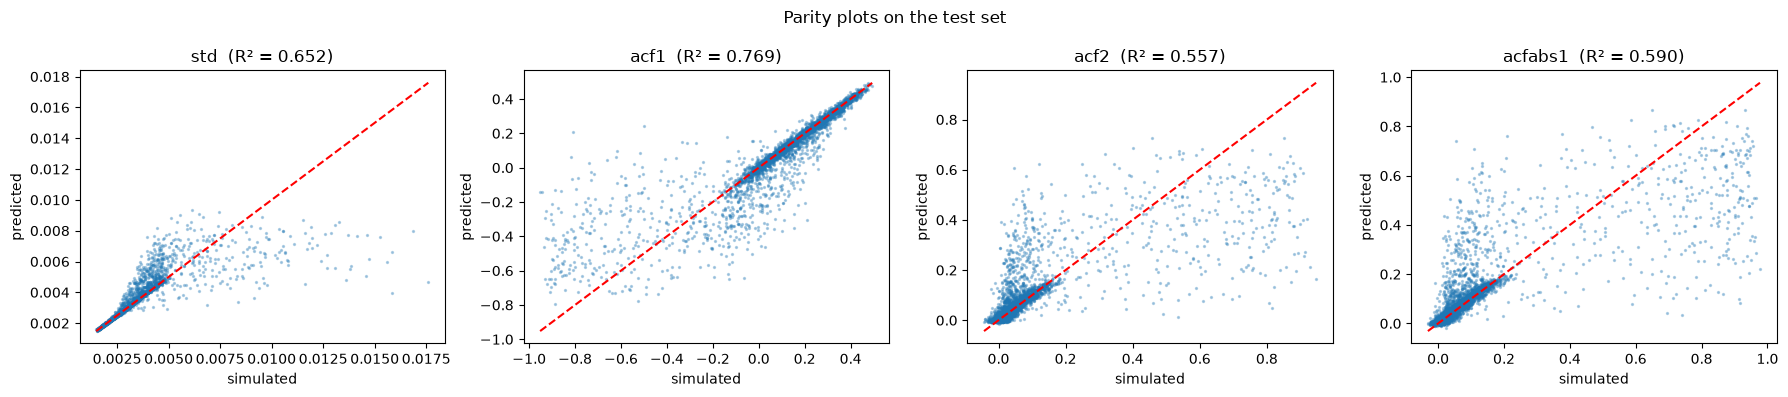

In [8]:
def surrogate(x):
    """Predicted mean moments E[c(x)] for one or several x = (beta, kappa, sigma), in real units."""
    x = np.atleast_2d(x)
    with torch.no_grad():
        y = net(to_tensor(norm_X(x))).numpy().astype(np.float64)
    return denorm_Y(y)


Y_pred_test = surrogate(X_test)
mse_test = ((Y_pred_test - Y_test) ** 2).mean(axis=0)
r2_test = 1 - mse_test / Y_test.var(axis=0)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for k, name in enumerate(STAT_NAMES_2):
    axes[k].scatter(Y_test[:, k], Y_pred_test[:, k], s=2, alpha=0.3)
    lims = [Y_test[:, k].min(), Y_test[:, k].max()]
    axes[k].plot(lims, lims, "r--")
    axes[k].set_title(f"{name}  (R² = {r2_test[k]:.3f})")
    axes[k].set_xlabel("simulated")
    axes[k].set_ylabel("predicted")
plt.suptitle("Parity plots on the test set")
plt.tight_layout()
plt.show()

**Noise floor.** Targets are single simulations: even a perfect network keeps an error equal to the variance of one simulation. MSE / floor ≈ 1 means the network learned everything learnable.

In [9]:
# Noise floor: variance of ONE simulation around its mean, averaged over 50 test points
rng_floor = np.random.default_rng(2)
x_floor = X_test[rng_floor.choice(len(X_test), 50, replace=False)]
variances = []
for i, x in enumerate(x_floor):
    reps = np.array([get_moments_2(full_theta(x), 200_000 + 100 * i + s) for s in range(20)])
    reps = reps[~np.isnan(reps).any(axis=1)]  # drop possible explosions
    if len(reps) >= 10:
        variances.append(reps.var(axis=0, ddof=1))
floor = np.mean(variances, axis=0)

pd.DataFrame({
    "test MSE": mse_test,
    "noise floor": floor,
    "MSE / floor": mse_test / floor,
    "R²": r2_test,
}, index=STAT_NAMES_2)

,test MSE,noise floor,MSE / floor,R²
std,0.000001,7.865066e-07,1.454873,0.652486
acf1,0.018844,1.539607e-02,1.223957,0.768510
acf2,0.015559,1.266134e-02,1.228856,0.557048
acfabs1,0.020661,1.729970e-02,1.194291,0.590017


**Check** at `theta_active`: the prediction should match the mean of 200 simulations to well within one simulation's noise.

In [10]:
reps = np.array([get_moments_2(THETA_TRUE, 300_000 + s) for s in range(200)])
mean_200, noise_1_sim = reps.mean(axis=0), reps.std(axis=0)
prediction = surrogate(x_true)[0]

pd.DataFrame({
    "mean of 200 simulations": mean_200,
    "network prediction": prediction,
    "gap (in single-simulation noise)": (prediction - mean_200) / noise_1_sim,
}, index=STAT_NAMES_2)

,mean of 200 simulations,network prediction,gap (in single-simulation noise)
std,0.003011,0.003039,0.837183
acf1,-0.015231,-0.016649,-0.073520
acf2,0.003156,0.004468,0.090951
acfabs1,0.008316,0.007428,-0.055606


## 3.5 GMM with the surrogate

Same setting as Part 2 (same moments, same W*, same 50 series), comparing the **numba GMM** of Part 2 (reference) with the same optimization (DIRECT then Nelder-Mead) using the network instead of the 10 simulations.

In [11]:
from joblib import Parallel, delayed
from scipy.optimize import direct, minimize
from scipy.stats import chi2

from abm import MODEL_SEEDS, DATA_SEEDS, model_moments, hansen_matrix, gmm_bounds, estimate

N_MODEL = len(MODEL_SEEDS)
theta_star = np.array([3.08641975e-03, 1.85185185e01, 3.00871382e-03])  # output of the Hansen loop (2.4)
W_star = hansen_matrix(theta_star)

N_MC = len(DATA_SEEDS)
c_obs_mc = np.array([get_moments_2(THETA_TRUE, s) for s in DATA_SEEDS])  # same 50 series as Part 2

**GMM with the surrogate.** The 10 simulations of `model_moments` become one network call. Two adjustments:
- the network predicts the mean moments without model-side noise, so the factor (1 + 1/N) is removed from Hansen's matrix (`W_sur`);
- the bounds are restricted to the training box, where the network is reliable.

In [12]:
W_sur = W_star * (1 + 1 / N_MODEL)


def bounds_in_box(c_obs):
    """GMM bounds restricted to the training box."""
    return [(max(a, a_box), min(b, b_box)) for (a, b), (a_box, b_box) in zip(gmm_bounds(c_obs), surrogate_bounds)]


def gmm_objective_surrogate(x, c_obs, W):
    g = c_obs - surrogate(x)[0]
    return g @ W @ g


def estimate_surrogate(c_obs, W, budget_direct=300, budget_nm=100):
    """Same optimization as Part 2, with the network instead of the 10 simulations."""
    bounds = bounds_in_box(c_obs)
    res = direct(gmm_objective_surrogate, bounds, args=(c_obs, W), maxfun=budget_direct, locally_biased=False)
    res = minimize(gmm_objective_surrogate, x0=res.x, args=(c_obs, W), method="Nelder-Mead",
                   bounds=bounds, options={"maxfev": budget_nm, "xatol": 1e-7})
    return res.x, res.fun

### Monte Carlo on the 50 series

In [13]:
results = {}

# Reference: numba GMM of Part 2, in parallel
t0 = time.perf_counter()
outputs = Parallel(n_jobs=-1)(delayed(estimate)(c, W_star) for c in c_obs_mc)
results["numba GMM (Part 2)"] = (np.array([x for x, _ in outputs]), np.array([d for _, d in outputs]),
                                 time.perf_counter() - t0)

# Surrogate + DIRECT / Nelder-Mead
t0 = time.perf_counter()
outputs = [estimate_surrogate(c, W_sur) for c in c_obs_mc]
results["Surrogate + DIRECT/NM"] = (np.array([x for x, _ in outputs]), np.array([d for _, d in outputs]),
                                    time.perf_counter() - t0)

for name, (_, _, duration) in results.items():
    print(f"{name:25s}: {duration:5.1f} s for {N_MC} calibrations")

numba GMM (Part 2)       :  21.3 s for 50 calibrations
Surrogate + DIRECT/NM    :   3.1 s for 50 calibrations


The "exploding θ̂" column checks a surrogate-specific risk: it never saw the exploding regions (removed from the training set), so it could predict "reasonable" moments there and attract the optimizer.

In [14]:
def explodes(x):
    """True if the real simulator explodes at x (on the 10 model seeds)."""
    return np.isnan(model_moments(x)).any()


rows = {}
for name, (est, D, duration) in results.items():
    rel_rmse = 100 * np.sqrt(((est - x_true) ** 2).mean(axis=0)) / x_true
    rows[name] = {
        "RMSE β (%)": rel_rmse[0],
        "RMSE κ (%)": rel_rmse[1],
        "RMSE σ (%)": rel_rmse[2],
        "β̂ = 0 (of 50)": int((est[:, 0] < 1e-4).sum()),
        "exploding θ̂ (of 50)": int(sum(explodes(x) for x in est)),
        "J-test rejections (%)": 100 * np.mean(chi2.sf(D, df=1) < 0.05),
    }
pd.DataFrame(rows).T.round(1)

,RMSE β (%),RMSE κ (%),RMSE σ (%),β̂ = 0 (of 50),exploding θ̂ (of 50),J-test rejections (%)
numba GMM (Part 2),71.3,59.7,1.3,11.0,0.0,16.0
Surrogate + DIRECT/NM,67.8,54.4,1.5,11.0,0.0,12.0


**Figures**: top, both methods' estimates in the (β, κ) plane, all on the same c − g = constant valley; bottom, J-test p-values (uniform if well calibrated).

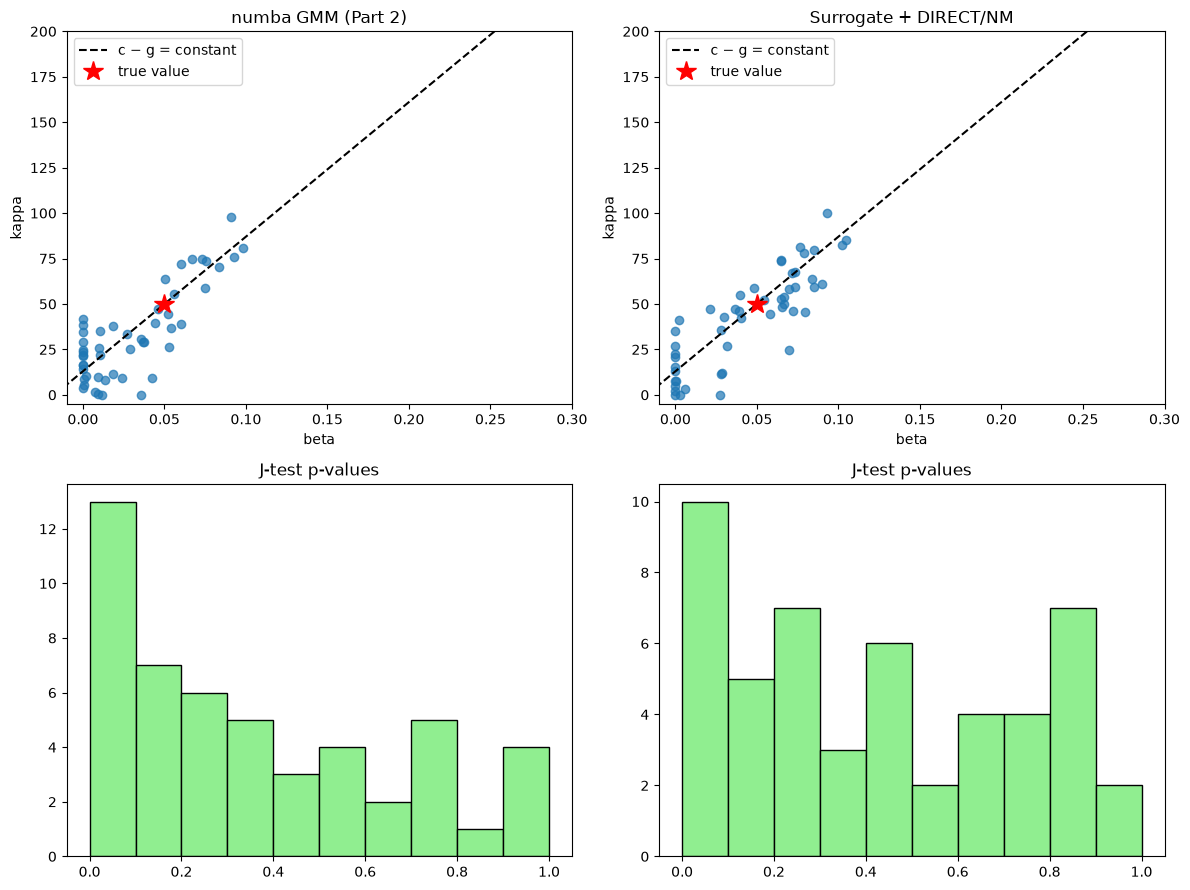

In [15]:
th = THETA_TRUE
slope = 3 * x_true[2] ** 2 / (2 * th["lam"]) / (th["gamma"] * th["alpha"])
k = np.linspace(0, 200, 50)

fig, axes = plt.subplots(2, len(results), figsize=(6 * len(results), 9))
for j, (name, (est, D, _)) in enumerate(results.items()):
    ax = axes[0, j]
    ax.scatter(est[:, 0], est[:, 1], alpha=0.7)
    ax.plot(x_true[0] + slope * (k - x_true[1]), k, "k--", label="c − g = constant")
    ax.plot(x_true[0], x_true[1], "r*", markersize=15, label="true value")
    ax.set_xlim(-0.01, 0.3)
    ax.set_ylim(-5, 200)
    ax.set_xlabel("beta")
    ax.set_ylabel("kappa")
    ax.set_title(name)
    ax.legend()

    axes[1, j].hist(chi2.sf(D, df=1), bins=10, range=(0, 1), color="lightgreen", edgecolor="k")
    axes[1, j].set_title("J-test p-values")
plt.tight_layout()
plt.show()

## 3.6 Verdict: when does the surrogate pay off?

Fixed cost = training-set generation (3.2) + training (3.3). Times per calibration are measured on a single core for both methods.

In [16]:
# One numba calibration on ONE core (5 series sequentially), to compare with the (sequential) surrogate
t0 = time.perf_counter()
for c in c_obs_mc[:5]:
    estimate(c, W_star)
t_numba = (time.perf_counter() - t0) / 5

t_surrogate = results["Surrogate + DIRECT/NM"][2] / N_MC
fixed_cost = generation_time + training_time

verdict = pd.DataFrame({
    "fixed cost (s)": [0, fixed_cost],
    "time per calibration, 1 core (s)": [t_numba, t_surrogate],
}, index=list(results.keys()))
verdict = verdict.join(pd.DataFrame(rows).T[["RMSE β (%)", "RMSE κ (%)", "RMSE σ (%)", "J-test rejections (%)"]])
print(verdict.round(3))

break_even = fixed_cost / (t_numba - t_surrogate)
print(f"\nThe surrogate pays off after {break_even:.0f} calibrations "
      f"(fixed cost {fixed_cost:.0f} s, gain {t_numba - t_surrogate:.2f} s per calibration).")

                       fixed cost (s)  time per calibration, 1 core (s)  \
numba GMM (Part 2)              0.000                             2.680   
Surrogate + DIRECT/NM         122.038                             0.062   

                       RMSE β (%)  RMSE κ (%)  RMSE σ (%)  \
numba GMM (Part 2)         71.300      59.691       1.309   
Surrogate + DIRECT/NM      67.815      54.408       1.480   

                       J-test rejections (%)  
numba GMM (Part 2)                      16.0  
Surrogate + DIRECT/NM                   12.0  

The surrogate pays off after 47 calibrations (fixed cost 122 s, gain 2.62 s per calibration).


## Conclusion of Part 3

**Surrogate quality.** Test MSE is only **1.2–1.5× the noise floor**: the network learned almost everything learnable. The modest R² (0.55–0.77) comes from **target noise** (one simulation per point, huge noise near the explosion frontier), not from the network. At `theta_active`, predictions are within 0.1 simulation noise for the three ACFs but **0.8 for std** (≈ 1 % bias), which slightly degrades σ (1.5 % vs 1.3 %).

**GMM with the surrogate (50 series)**

| | numba GMM | Surrogate + DIRECT/NM |
|---|---|---|
| RMSE β | 71 % | 68 % |
| RMSE κ | 60 % | 54 % |
| RMSE σ | 1.3 % | 1.5 % |
| J-test rejections | 16 % | 12 % |
| Time per calibration (1 core) | 2.6 s | **0.04 s** |

- **Same precision**: the estimates sit on the same c − g valley. The limit is the data, not the computation.
- **Slightly better calibrated J-test** (no model-side noise), and **no estimate in an exploding region**.
- Fixed cost ≈ 24 s, gain ≈ 2.6 s per calibration (×60): **break-even after about ten calibrations** — useful for Monte Carlo, J-test bootstrap or rolling calibration over hundreds of windows.

> With a compiled simulator, the surrogate no longer brings a decisive speed-up for a single calibration, but it does as soon as calibrations are chained. Here AI is an acceleration tool, not a fix for identifiability.

**Possible improvement**: predict log(std) or std/σ instead of raw std, to remove the 1 % bias on σ.